**Programme Title:** HDIP Data Analytics

**Module Title(s):** Machine Learning for Business

**Assignment Title:** CA1

**Lecturer(s):** Dr. Muhammad Iqbal

**Student name:** Battsengel Gantsooj

**Student ID:** 2026124

**Submission date:** 30/10/2026


## Importing variables

In [1]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.1.3


In [2]:
import sys

print(sys.executable)

/usr/bin/python3


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Loading

Combining all 6 months of the raw .csv data that's avaible in a sinle .csv file


January = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202101-divvy-tripdata.csv")

February = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202102-divvy-tripdata.csv")

March = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202103-divvy-tripdata.csv")

April = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202104-divvy-tripdata.csv")

May = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202105-divvy-tripdata.csv")

June = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202106-divvy-tripdata.csv")

In [ ]:
January = pd.read_csv("/Raw Dataset/202101-divvy-tripdata.csv")
February = pd.read_csv("/Raw Dataset/202102-divvy-tripdata.csv")
March = pd.read_csv("/Raw Dataset/202103-divvy-tripdata.csv")
April = pd.read_csv("/Raw Dataset/202104-divvy-tripdata.csv")
May = pd.read_csv("/Raw Dataset/202105-divvy-tripdata.csv")
June = pd.read_csv("/Raw Dataset/202106-divvy-tripdata.csv")

## conbininng all the dataset available to one dastaet
transport = pd.concat([January, February, March, April, May, June], ignore_index=True)

transport.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973410 entries, 0 to 1973409
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 195.7+ MB


In [5]:
print("January:", len(January))
print("February:", len(February))
print("March:", len(March))
print("April:", len(April))
print("May:", len(May))
print("June:", len(June))
print("Combined:", len(transport))

January: 96834
February: 49622
March: 228496
April: 337230
May: 531633
June: 729595
Combined: 1973410


## Data Expolaration

In [6]:
transport.shape

transport.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E19E6F1B8D4C42ED,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member
1,DC88F20C2C55F27F,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member
2,EC45C94683FE3F27,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member
3,4FA453A75AE377DB,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member
4,BE5E8EB4E7263A0B,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual


In [7]:
transport.isnull().sum()


,0
ride_id,0
rideable_type,0
started_at,0
ended_at,0
start_station_name,187412
start_station_id,187412
end_station_name,205117
end_station_id,205117
start_lat,0
start_lng,0


changing datatype of started_at , ended_at from object to datetime and removing column ride_id as it is useless


In [8]:
transport = transport.drop(columns=['ride_id'])
transport['started_at'] = pd.to_datetime(transport['started_at'])
transport['ended_at'] =  pd.to_datetime(transport['ended_at'])
transport.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973410 entries, 0 to 1973409
Data columns (total 12 columns):
 #   Column              Dtype         
---  ------              -----         
 0   rideable_type       object        
 1   started_at          datetime64[ns]
 2   ended_at            datetime64[ns]
 3   start_station_name  object        
 4   start_station_id    object        
 5   end_station_name    object        
 6   end_station_id      object        
 7   start_lat           float64       
 8   start_lng           float64       
 9   end_lat             float64       
 10  end_lng             float64       
 11  member_casual       object        
dtypes: datetime64[ns](2), float64(4), object(6)
memory usage: 180.7+ MB


In [9]:
transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual


In [10]:
transport['ride_length'] = transport['ended_at'] - transport['started_at']
transport['ride_length_in_seconds'] = transport['ride_length'].dt.total_seconds()
transport['ride_length_in_seconds'].describe()

,ride_length_in_seconds
count,1.973410e+06
mean,1.487623e+03
std,1.344890e+04
min,-3.060000e+02
25%,4.340000e+02
50%,7.780000e+02
75%,1.427000e+03
max,3.356649e+06


In [11]:
# transport.info()
transport['date'] = transport['started_at'].dt.date
transport['day_name'] = transport['started_at'].dt.day_name()
transport['day'] = transport['started_at'].dt.day
transport['month'] = transport['started_at'].dt.month
transport['year'] = transport['started_at'].dt.year
transport.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973410 entries, 0 to 1973409
Data columns (total 19 columns):
 #   Column                  Dtype          
---  ------                  -----          
 0   rideable_type           object         
 1   started_at              datetime64[ns] 
 2   ended_at                datetime64[ns] 
 3   start_station_name      object         
 4   start_station_id        object         
 5   end_station_name        object         
 6   end_station_id          object         
 7   start_lat               float64        
 8   start_lng               float64        
 9   end_lat                 float64        
 10  end_lng                 float64        
 11  member_casual           object         
 12  ride_length             timedelta64[ns]
 13  ride_length_in_seconds  float64        
 14  date                    object         
 15  day_name                object         
 16  day                     int32          
 17  month                   int

In [12]:
###

In [13]:
transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_length,ride_length_in_seconds,date,day_name,day,month,year
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member,0 days 00:10:25,625.0,2021-01-23,Saturday,23,1,2021
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member,0 days 00:04:04,244.0,2021-01-27,Wednesday,27,1,2021
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member,0 days 00:01:20,80.0,2021-01-21,Thursday,21,1,2021
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member,0 days 00:11:42,702.0,2021-01-07,Thursday,7,1,2021
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual,0 days 00:00:43,43.0,2021-01-23,Saturday,23,1,2021


### Using earth cordinates to calculate distance we already have longitude and latitude of both starting and ending point ( https://en.wikipedia.org/wiki/Haversine_formula ) using haverine formula

In [14]:
def haversine (lat1, lon1, lat2, lon2):
    earth_radius = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius * c

transport['distance_km'] = haversine(
    transport['start_lat'],
    transport['start_lng'],
    transport['end_lat'],
    transport['end_lng'])

# transport['distance_m'] = transport['distance_km']*1000

transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_length,ride_length_in_seconds,date,day_name,day,month,year,distance_km
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member,0 days 00:10:25,625.0,2021-01-23,Saturday,23,1,2021,2.242244
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member,0 days 00:04:04,244.0,2021-01-27,Wednesday,27,1,2021,0.556327
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member,0 days 00:01:20,80.0,2021-01-21,Thursday,21,1,2021,0.280031
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member,0 days 00:11:42,702.0,2021-01-07,Thursday,7,1,2021,2.248210
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual,0 days 00:00:43,43.0,2021-01-23,Saturday,23,1,2021,0.275752


In [15]:
transport['avg_speed_kmh'] = (transport['distance_km'] / (transport['ride_length_in_seconds'] / 3600))
transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,...,member_casual,ride_length,ride_length_in_seconds,date,day_name,day,month,year,distance_km,avg_speed_kmh
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,...,member,0 days 00:10:25,625.0,2021-01-23,Saturday,23,1,2021,2.242244,12.915324
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,...,member,0 days 00:04:04,244.0,2021-01-27,Wednesday,27,1,2021,0.556327,8.208101
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,...,member,0 days 00:01:20,80.0,2021-01-21,Thursday,21,1,2021,0.280031,12.601402
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,...,member,0 days 00:11:42,702.0,2021-01-07,Thursday,7,1,2021,2.248210,11.529283
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,...,casual,0 days 00:00:43,43.0,2021-01-23,Saturday,23,1,2021,0.275752,23.086200


In [16]:
transport['avg_speed_kmh'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,avg_speed_kmh
count,1.971458e+06
mean,inf
std,NaN
min,-2.000403e+03
1%,0.000000e+00
5%,0.000000e+00
10%,4.841608e-01
25%,5.853441e+00
50%,9.668931e+00
75%,1.248300e+01


removing outliners as infinite speed is not possible and as 5th percentile shows 0km/hr it means thy have covered 0 distance.

In [17]:
transport_final = transport[(transport['avg_speed_kmh'] >= 3) & (transport['avg_speed_kmh'] <= 20)].copy()

In [18]:
transport_final['avg_speed_kmh'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,avg_speed_kmh
count,1.624894e+06
mean,1.054398e+01
std,3.513491e+00
min,3.000004e+00
1%,3.336417e+00
5%,4.578368e+00
10%,5.807982e+00
25%,8.099521e+00
50%,1.051613e+01
75%,1.293516e+01


In [19]:
transport_final.columns.tolist()

['rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'end_station_id',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual',
 'ride_length',
 'ride_length_in_seconds',
 'date',
 'day_name',
 'day',
 'month',
 'year',
 'distance_km',
 'avg_speed_kmh']

In [20]:
print("Dataset shape:", transport_final.shape)

print("\nData types:")
print(transport_final.dtypes)


Dataset shape: (1624894, 21)

Data types:
rideable_type                      object
started_at                 datetime64[ns]
ended_at                   datetime64[ns]
start_station_name                 object
start_station_id                   object
end_station_name                   object
end_station_id                     object
start_lat                         float64
start_lng                         float64
end_lat                           float64
end_lng                           float64
member_casual                      object
ride_length               timedelta64[ns]
ride_length_in_seconds            float64
date                               object
day_name                           object
day                                 int32
month                               int32
year                                int32
distance_km                       float64
avg_speed_kmh                     float64
dtype: object


In [21]:
print("\nMissing values:")
print(transport_final.isnull().sum())

print("\nDuplicate rows:", transport_final.duplicated().sum())


Missing values:
rideable_type                  0
started_at                     0
ended_at                       0
start_station_name        144185
start_station_id          144185
end_station_name          152376
end_station_id            152376
start_lat                      0
start_lng                      0
end_lat                        0
end_lng                        0
member_casual                  0
ride_length                    0
ride_length_in_seconds         0
date                           0
day_name                       0
day                            0
month                          0
year                           0
distance_km                    0
avg_speed_kmh                  0
dtype: int64

Duplicate rows: 145


### Dataset Cleaning finish
now checkng data for for Exploratory Data Analysis (EDA)

## Exploratory Data Analysis (EDA)

In [22]:
# Visualise the result
import matplotlib.pyplot as plt

# Work with a copy so your cleaned dataset stays unchanged
df = transport_final.copy()

# Convert date to a proper datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Display plots inside the notebook
%matplotlib inline

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 1624894
Columns: 21


##### Checking Quality of the data

In [23]:
print("DATASET SHAPE")
print(df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nNUMERICAL SUMMARY")
print(df[[
    "ride_length_in_seconds",
    "distance_km",
    "avg_speed_kmh"
]].describe())

print("\nDATE RANGE")
print("Start:", df["started_at"].min())
print("End:", df["started_at"].max())

print("\nUSER TYPES")
print(df["member_casual"].value_counts(dropna=False))

print("\nBIKE TYPES")
print(df["rideable_type"].value_counts(dropna=False))


DATASET SHAPE
(1624894, 21)

MISSING VALUES
end_station_name          152376
end_station_id            152376
start_station_id          144185
start_station_name        144185
rideable_type                  0
started_at                     0
ended_at                       0
start_lat                      0
start_lng                      0
end_lat                        0
end_lng                        0
member_casual                  0
ride_length                    0
ride_length_in_seconds         0
date                           0
day_name                       0
day                            0
month                          0
year                           0
distance_km                    0
avg_speed_kmh                  0
dtype: int64

DUPLICATE ROWS
145

NUMERICAL SUMMARY
       ride_length_in_seconds   distance_km  avg_speed_kmh
count            1.624894e+06  1.624894e+06   1.624894e+06
mean             9.170064e+02  2.495407e+00   1.054398e+01
std              7.644422e+02  1.9

Checking if there is any suspicious value

In [24]:
print("Zero or negative ride durations:",
      (df["ride_length_in_seconds"] <= 0).sum())

print("Negative distances:",
      (df["distance_km"] < 0).sum())

print("Infinite estimated speeds:",
      np.isinf(df["avg_speed_kmh"]).sum())

print("Missing estimated speeds:",
      df["avg_speed_kmh"].isna().sum())

print("Negative estimated speeds:",
      (df["avg_speed_kmh"] < 0).sum())

Zero or negative ride durations: 0
Negative distances: 0
Infinite estimated speeds: 0
Missing estimated speeds: 0
Negative estimated speeds: 0


Compare bike-type preferences

In [25]:
# Count trips by rider category and bike type
bike_counts = pd.crosstab(
    df["member_casual"],
    df["rideable_type"]
)

print("Trip counts:")
display(bike_counts)

# Calculate percentages within each rider category
bike_percentages = pd.crosstab(
    df["member_casual"],
    df["rideable_type"],
    normalize="index"
) * 100

print("Percentage of each rider category using each bike type:")
display(bike_percentages.round(2))

Trip counts:


rideable_type,classic_bike,docked_bike,electric_bike
member_casual,,,
casual,334469,69933,233306
member,700225,1,286960


Percentage of each rider category using each bike type:


rideable_type,classic_bike,docked_bike,electric_bike
member_casual,,,
casual,52.45,10.97,36.59
member,70.93,0.00,29.07


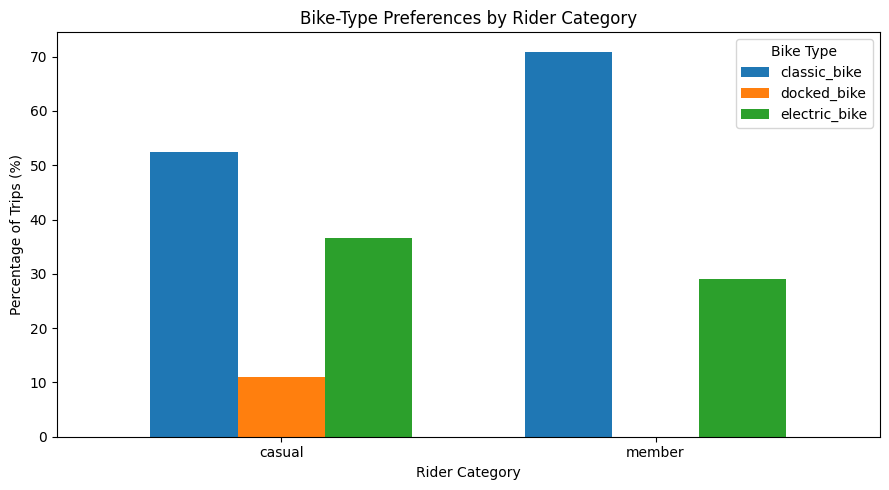

In [26]:
ax = bike_percentages.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

ax.set_title("Bike-Type Preferences by Rider Category")
ax.set_xlabel("Rider Category")
ax.set_ylabel("Percentage of Trips (%)")
ax.legend(title="Bike Type")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### How does usage vary by day of the week?
Count trips by day and rider category

In [27]:
# Define weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Count trips by weekday and rider category
weekday_counts = pd.crosstab(
    df["day_name"],
    df["member_casual"]
).reindex(weekday_order)

display(weekday_counts)

member_casual,casual,member
day_name,,
Monday,69890,135645
Tuesday,73414,150535
Wednesday,72584,154398
Thursday,65843,133687
Friday,90234,141841
Saturday,143961,144821
Sunday,121782,126259


Plot weekday usage

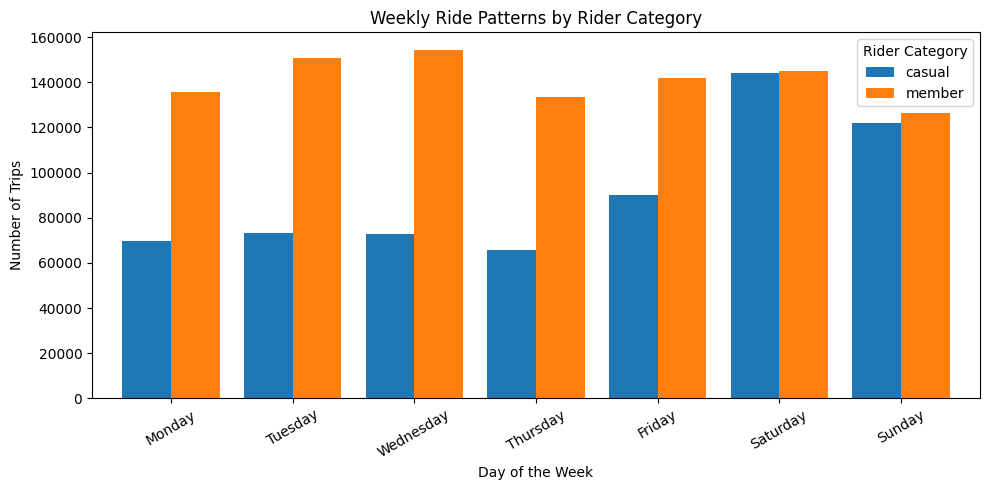

In [28]:
ax = weekday_counts.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Weekly Ride Patterns by Rider Category")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Number of Trips")
ax.legend(title="Rider Category")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Compare the distribution fairly

member_casual,casual,member
day_name,,
Monday,10.96,13.74
Tuesday,11.51,15.25
Wednesday,11.38,15.64
Thursday,10.32,13.54
Friday,14.15,14.37
Saturday,22.57,14.67
Sunday,19.10,12.79


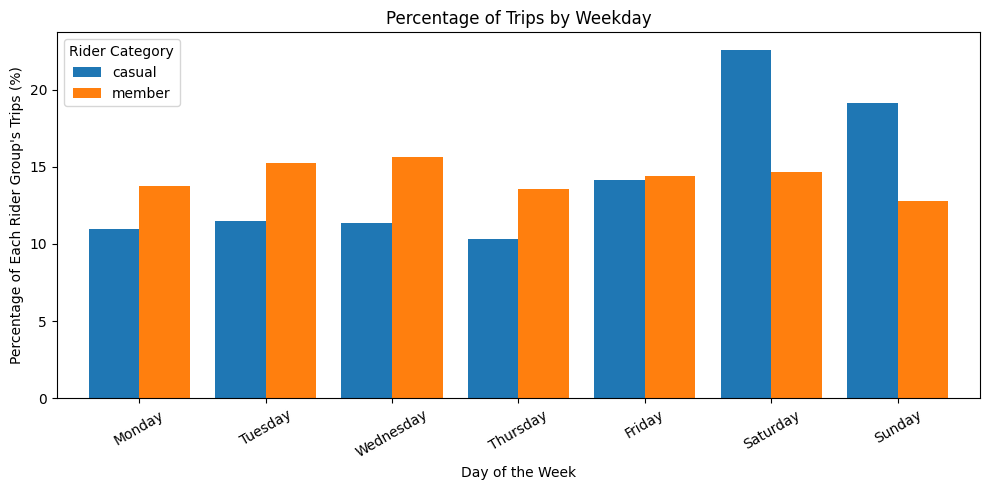

In [29]:
weekday_percentages = (
    pd.crosstab(
        df["day_name"],
        df["member_casual"],
        normalize="columns"
    ) * 100
).reindex(weekday_order)

display(weekday_percentages.round(2))

ax = weekday_percentages.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Percentage of Trips by Weekday")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Percentage of Each Rider Group's Trips (%)")
ax.legend(title="Rider Category")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Monthly usage patterns
Calculate monthly trip counts

In [30]:
monthly_counts = pd.crosstab(
    df["month"],
    df["member_casual"]
).reindex(range(1, 7), fill_value=0)

monthly_counts.index = [
    "January", "February", "March",
    "April", "May", "June"
]

display(monthly_counts)

member_casual,casual,member
January,14382,71434
February,7448,34976
March,58497,130631
April,96532,180260
May,183761,247135
June,277088,322750


Monthly usage Plot

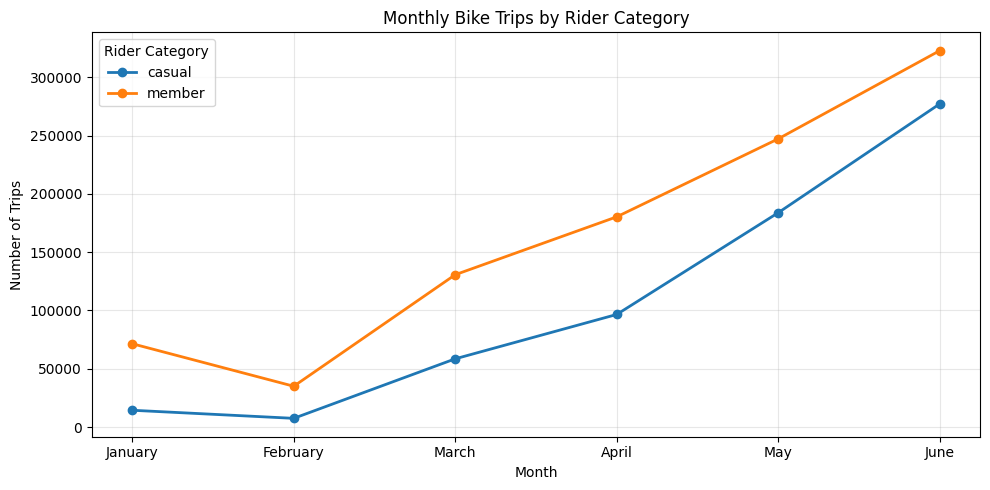

In [31]:
ax = monthly_counts.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    linewidth=2
)

ax.set_title("Monthly Bike Trips by Rider Category")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Trips")
ax.legend(title="Rider Category")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Monthly share of each rider category

In [32]:
monthly_percentages = (
    pd.crosstab(
        df["month"],
        df["member_casual"],
        normalize="columns"
    ) * 100
).reindex(range(1, 7), fill_value=0)

monthly_percentages.index = [
    "January", "February", "March",
    "April", "May", "June"
]

display(monthly_percentages.round(2))

member_casual,casual,member
January,2.26,7.24
February,1.17,3.54
March,9.17,13.23
April,15.14,18.26
May,28.82,25.03
June,43.45,32.69


Average daily trips by month

In [33]:
# Count trips per day for each rider category
daily_rider_counts = (
    df.groupby(["date", "member_casual"])
      .size()
      .unstack(fill_value=0)
)

# Average daily trips within each month
daily_rider_counts["month"] = daily_rider_counts.index.month

avg_daily_trips = (
    daily_rider_counts
    .groupby("month")[["casual", "member"]]
    .mean()
    .reindex(range(1, 7))
)

avg_daily_trips.index = [
    "January", "February", "March",
    "April", "May", "June"
]

display(avg_daily_trips.round(0))

member_casual,casual,member
January,464.0,2304.0
February,266.0,1249.0
March,1887.0,4214.0
April,3218.0,6009.0
May,5928.0,7972.0
June,9236.0,10758.0


Average daily demand Plot

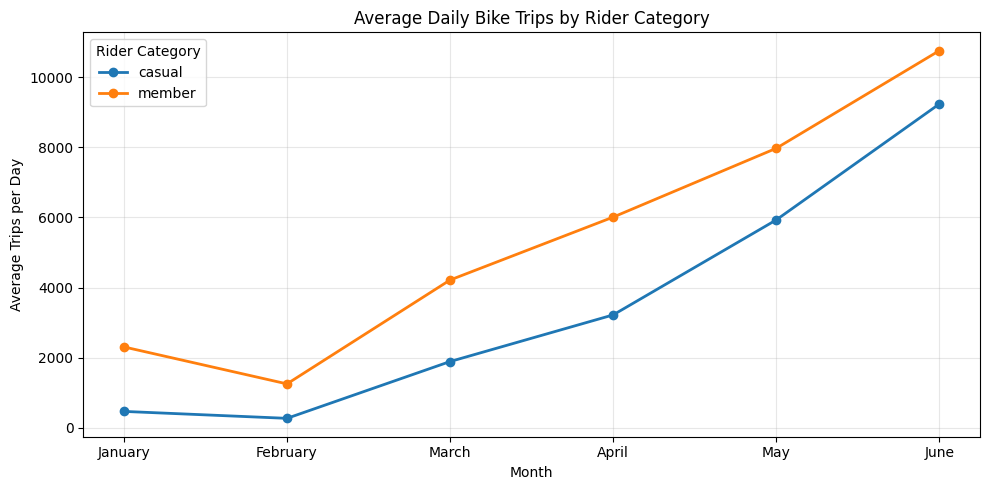

In [34]:
ax = avg_daily_trips.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    linewidth=2
)

ax.set_title("Average Daily Bike Trips by Rider Category")
ax.set_xlabel("Month")
ax.set_ylabel("Average Trips per Day")
ax.legend(title="Rider Category")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Comparing ride duration
Summary statistics

In [35]:
duration_summary = (
    df.groupby("member_casual")["ride_length_in_seconds"]
      .agg(["count", "mean", "median", "std", "min", "max"])
)

duration_summary["mean_minutes"] = (
    duration_summary["mean"] / 60
)

duration_summary["median_minutes"] = (
    duration_summary["median"] / 60
)

display(duration_summary.round(2))

,count,mean,median,std,min,max,mean_minutes,median_minutes
member_casual,,,,,,,,
casual,637708,1140.51,882.0,941.51,1.0,19726.0,19.01,14.7
member,987186,772.62,606.0,579.76,1.0,11717.0,12.88,10.1


Comparing duration distributions

<Figure size 900x500 with 0 Axes>

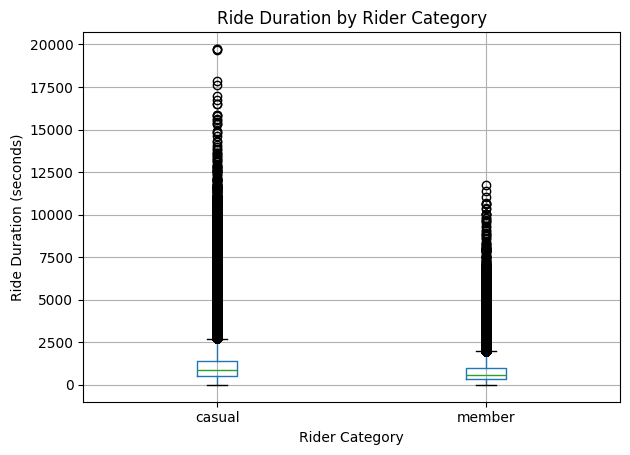

In [36]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column="ride_length_in_seconds",
    by="member_casual"
)

plt.title("Ride Duration by Rider Category")
plt.suptitle("")
plt.xlabel("Rider Category")
plt.ylabel("Ride Duration (seconds)")
plt.tight_layout()
plt.show()

Comparing median durations in minutes

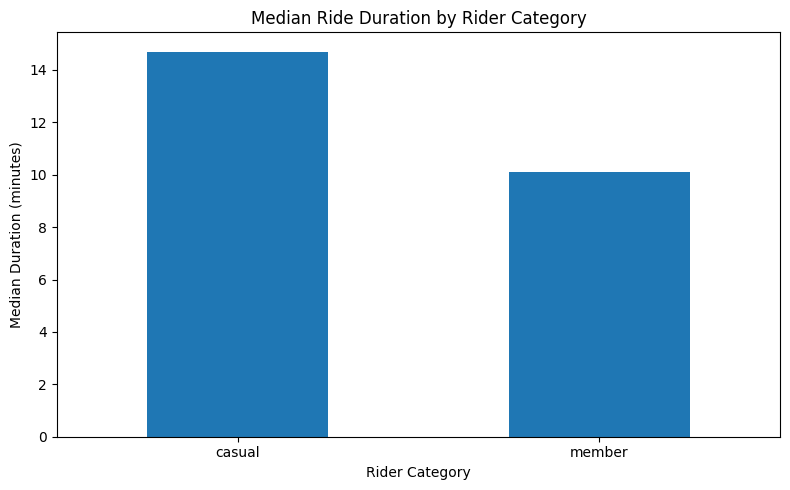

In [37]:
median_duration = (
    df.groupby("member_casual")["ride_length_in_seconds"]
      .median() / 60
)

ax = median_duration.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Median Ride Duration by Rider Category")
ax.set_xlabel("Rider Category")
ax.set_ylabel("Median Duration (minutes)")

plt.tight_layout()
plt.show()

### Comparing ride distances
Distance Summary

In [38]:
distance_summary = (
    df.groupby("member_casual")["distance_km"]
      .agg(["count", "mean", "median", "std", "min", "max"])
)

display(distance_summary.round(2))

,count,mean,median,std,min,max
member_casual,,,,,,
casual,637708,2.75,2.18,2.05,0.0,30.39
member,987186,2.33,1.76,1.85,0.0,32.02


Distance distribution

<Figure size 900x500 with 0 Axes>

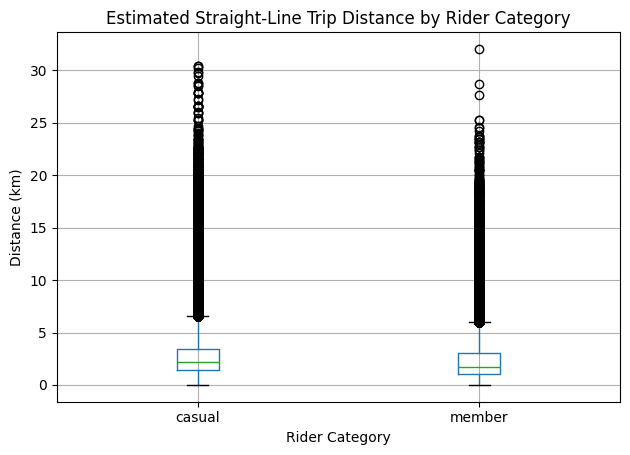

In [39]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column="distance_km",
    by="member_casual"
)

plt.title("Estimated Straight-Line Trip Distance by Rider Category")
plt.suptitle("")
plt.xlabel("Rider Category")
plt.ylabel("Distance (km)")
plt.tight_layout()
plt.show()

Comparing median distance

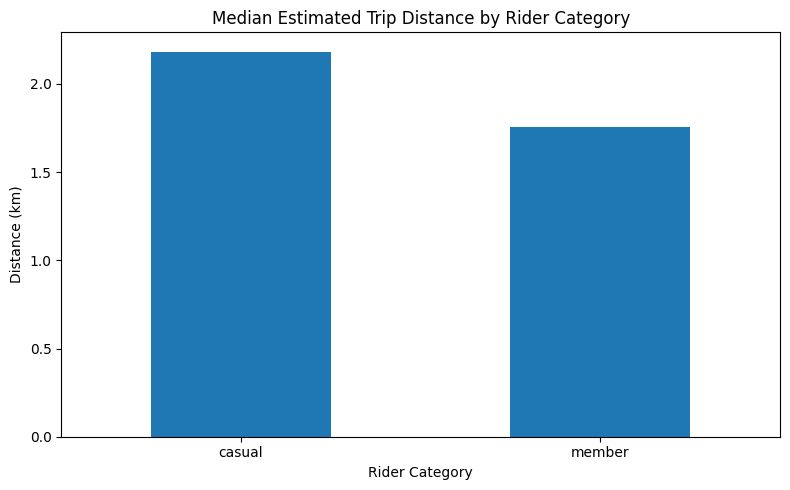

In [40]:
median_distance = (
    df.groupby("member_casual")["distance_km"]
      .median()
)

ax = median_distance.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Median Estimated Trip Distance by Rider Category")
ax.set_xlabel("Rider Category")
ax.set_ylabel("Distance (km)")

plt.tight_layout()
plt.show()

Checking zero distances and feature relationships

In [41]:
# Investigate zero-distance rides
zero_distance = df[df["distance_km"] == 0]

print("Zero-distance trips:", len(zero_distance))

print("\nZero-distance trips by rider category:")
print(zero_distance["member_casual"].value_counts())

print("\nZero-distance trips by bike type:")
print(zero_distance["rideable_type"].value_counts())

# Check relationships between numerical features
features = [
    "ride_length_in_seconds",
    "distance_km",
    "avg_speed_kmh"
]

display(df[features].corr().round(3))

Zero-distance trips: 0

Zero-distance trips by rider category:
Series([], Name: count, dtype: int64)

Zero-distance trips by bike type:
Series([], Name: count, dtype: int64)


,ride_length_in_seconds,distance_km,avg_speed_kmh
ride_length_in_seconds,1.000,0.788,-0.255
distance_km,0.788,1.000,0.243
avg_speed_kmh,-0.255,0.243,1.000


## clustering features
1. ride_length_in_seconds

2. distance_km

Creating the clustering sample

In [42]:
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "ride_length_in_seconds",
    "distance_km"
]

# Keep complete observations for the selected features
cluster_df = df[cluster_features].replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Take a reproducible random sample
cluster_sample = cluster_df.sample(
    n=min(20000, len(cluster_df)),
    random_state=42
).copy()

# Scale the selected features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    cluster_sample[cluster_features]
)

print("Original usable observations:", len(cluster_df))
print("Sample size:", len(cluster_sample))
print("Scaled feature shape:", X_scaled.shape)

Original usable observations: 1624894
Sample size: 20000
Scaled feature shape: (20000, 2)


## Visualise the sampled trips

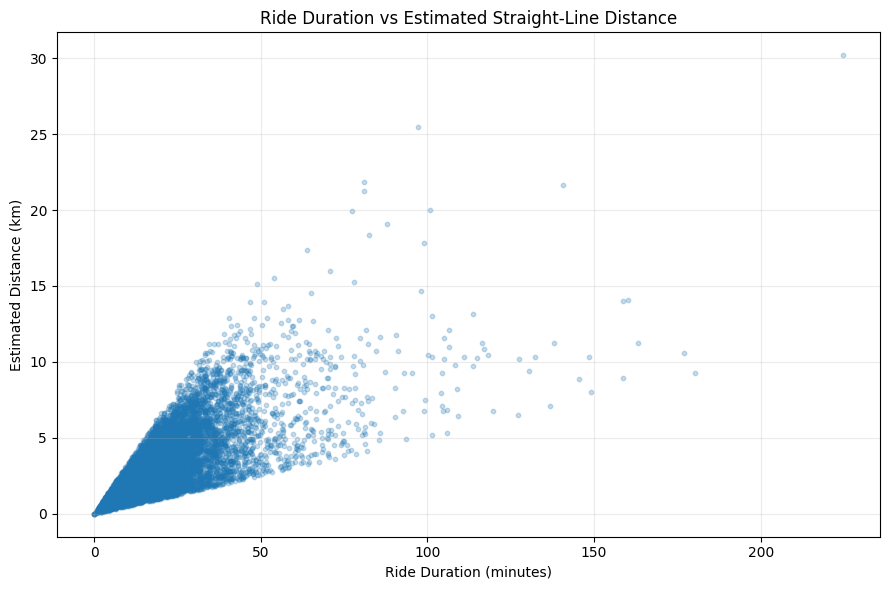

In [43]:
plt.figure(figsize=(9, 6))

plt.scatter(
    cluster_sample["ride_length_in_seconds"] / 60,
    cluster_sample["distance_km"],
    alpha=0.25,
    s=10
)

plt.title("Ride Duration vs Estimated Straight-Line Distance")
plt.xlabel("Ride Duration (minutes)")
plt.ylabel("Estimated Distance (km)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## clustering algorithm, K-Means
We'll compare several values of \(k\), from 2 to 6, using your 20,000-trip sample
1. Silhouette Score:
2. Davies-Bouldin Index (DBI)

Fit K-Means and evaluate the clusters

In [44]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd

results = []

for k in range(2, 7):
    print(f"Evaluating K-Means with k={k}...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    # Silhouette on a reproducible subset to reduce computation
    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    # DBI on the full 20,000-row sample
    dbi = davies_bouldin_score(X_scaled, labels)

    results.append({
        "k": k,
        "silhouette_score": silhouette,
        "davies_bouldin_index": dbi,
        "inertia": model.inertia_
    })

kmeans_results = pd.DataFrame(results)

display(kmeans_results.round(4))


Evaluating K-Means with k=2...
Evaluating K-Means with k=3...
Evaluating K-Means with k=4...
Evaluating K-Means with k=5...
Evaluating K-Means with k=6...


,k,silhouette_score,davies_bouldin_index,inertia
0,2,0.6101,0.7115,18211.2061
1,3,0.5311,0.7840,11911.1597
2,4,0.4896,0.8287,9117.9192
3,5,0.4403,0.8656,7420.2181
4,6,0.4537,0.8103,6220.3554


Comparing the evaluation metrics

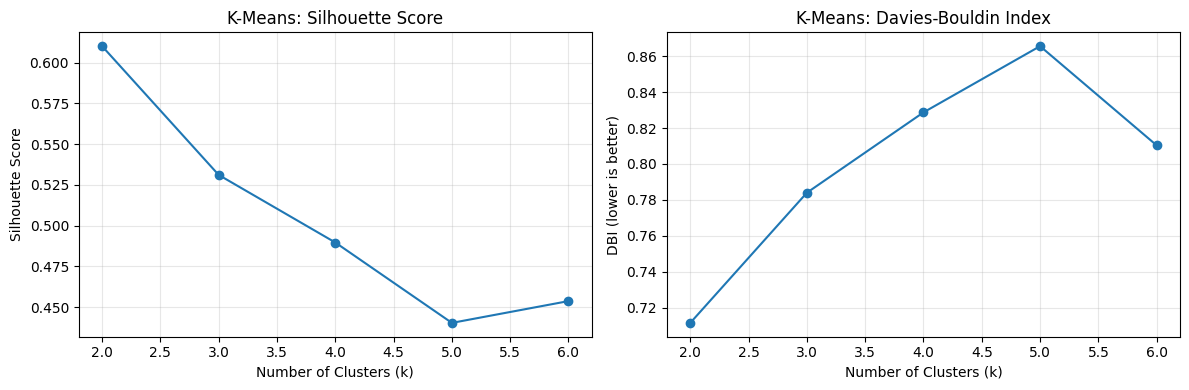

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    kmeans_results["k"],
    kmeans_results["silhouette_score"],
    marker="o"
)
axes[0].set_title("K-Means: Silhouette Score")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid(alpha=0.3)

axes[1].plot(
    kmeans_results["k"],
    kmeans_results["davies_bouldin_index"],
    marker="o"
)
axes[1].set_title("K-Means: Davies-Bouldin Index")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("DBI (lower is better)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Profilng the 2 K-Means clusters
Fit and profile K-Means

In [46]:
from sklearn.cluster import KMeans

# Fit the selected K-Means model
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_sample["kmeans_cluster"] = kmeans_final.fit_predict(X_scaled)

# Summarise cluster sizes
cluster_sizes = (
    cluster_sample["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

print("Cluster sizes:")
display(cluster_sizes.to_frame("number_of_trips"))

# Summarise duration and distance in their original units
cluster_profile = (
    cluster_sample
    .groupby("kmeans_cluster")
    .agg(
        trip_count=("ride_length_in_seconds", "size"),
        median_duration_seconds=("ride_length_in_seconds", "median"),
        mean_duration_seconds=("ride_length_in_seconds", "mean"),
        median_distance_km=("distance_km", "median"),
        mean_distance_km=("distance_km", "mean")
    )
)

cluster_profile["median_duration_minutes"] = (
    cluster_profile["median_duration_seconds"] / 60
)

cluster_profile["mean_duration_minutes"] = (
    cluster_profile["mean_duration_seconds"] / 60
)

display(cluster_profile.round(2))

Cluster sizes:


,number_of_trips
kmeans_cluster,
0,4239
1,15761


,trip_count,median_duration_seconds,mean_duration_seconds,median_distance_km,mean_distance_km,median_duration_minutes,mean_duration_minutes
kmeans_cluster,,,,,,,
0,4239,1729.0,1975.63,4.82,5.32,28.82,32.93
1,15761,578.0,635.06,1.58,1.73,9.63,10.58


Visualising the assigned cluster

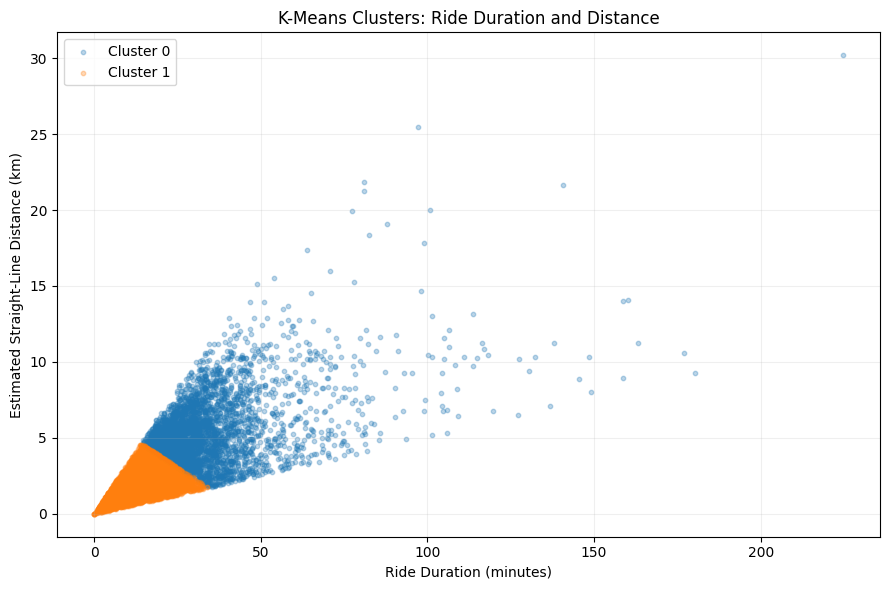

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster_id, group in cluster_sample.groupby("kmeans_cluster"):
    plt.scatter(
        group["ride_length_in_seconds"] / 60,
        group["distance_km"],
        alpha=0.3,
        s=10,
        label=f"Cluster {cluster_id}"
    )

plt.title("K-Means Clusters: Ride Duration and Distance")
plt.xlabel("Ride Duration (minutes)")
plt.ylabel("Estimated Straight-Line Distance (km)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

#### Adding rider category to the cluster profiles

Cluster 0: casual riders account for 49.89% of trips, almost equal to members at 50.11%.



Cluster 1: members account for 63.95% of trips, compared with 36.05% casual riders.

In [48]:
# Attach rider category to the sampled observations
cluster_sample["member_casual"] = df.loc[
    cluster_sample.index, "member_casual"
]

# Count rider categories within each cluster
cluster_rider_counts = pd.crosstab(
    cluster_sample["kmeans_cluster"],
    cluster_sample["member_casual"]
)

display(cluster_rider_counts)

# Percentages within each cluster
cluster_rider_percentages = pd.crosstab(
    cluster_sample["kmeans_cluster"],
    cluster_sample["member_casual"],
    normalize="index"
) * 100

display(cluster_rider_percentages.round(2))

member_casual,casual,member
kmeans_cluster,,
0,2115,2124
1,5682,10079


member_casual,casual,member
kmeans_cluster,,
0,49.89,50.11
1,36.05,63.95


## Second clustering algorithm : Agglomerative Clustering

In [49]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

# Create a reproducible sample for hierarchical clustering
agg_sample = cluster_df.sample(
    n=min(5000, len(cluster_df)),
    random_state=42
).copy()

# Scale features on this sample
agg_scaler = StandardScaler()
X_agg = agg_scaler.fit_transform(
    agg_sample[["ride_length_in_seconds", "distance_km"]]
)

agg_results = []

for k in range(2, 6):
    print(f"Evaluating Agglomerative Clustering with k={k}...")

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_agg)

    silhouette = silhouette_score(
        X_agg,
        labels,
        sample_size=min(2000, len(X_agg)),
        random_state=42
    )

    dbi = davies_bouldin_score(X_agg, labels)

    agg_results.append({
        "k": k,
        "silhouette_score": silhouette,
        "davies_bouldin_index": dbi
    })

agg_results = pd.DataFrame(agg_results)
display(agg_results.round(4))

Evaluating Agglomerative Clustering with k=2...
Evaluating Agglomerative Clustering with k=3...
Evaluating Agglomerative Clustering with k=4...
Evaluating Agglomerative Clustering with k=5...


,k,silhouette_score,davies_bouldin_index
0,2,0.6209,0.7070
1,3,0.4637,0.9074
2,4,0.4671,1.0022
3,5,0.3679,0.9980


## Compare both algorithms:: Agglomerative VS K-Means

In [50]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Use the same observations and scaling for both algorithms
comparison_sample = cluster_df.sample(
    n=min(5000, len(cluster_df)),
    random_state=42
).copy()

comparison_features = [
    "ride_length_in_seconds",
    "distance_km"
]

comparison_scaler = StandardScaler()
X_compare = comparison_scaler.fit_transform(
    comparison_sample[comparison_features]
)

comparison_results = []

for algorithm in ["K-Means", "Agglomerative"]:
    if algorithm == "K-Means":
        model = KMeans(
            n_clusters=2,
            random_state=42,
            n_init=10
        )
    else:
        model = AgglomerativeClustering(
            n_clusters=2,
            linkage="ward"
        )

    labels = model.fit_predict(X_compare)

    silhouette = silhouette_score(
        X_compare,
        labels,
        sample_size=min(2000, len(X_compare)),
        random_state=42
    )

    dbi = davies_bouldin_score(X_compare, labels)

    comparison_results.append({
        "algorithm": algorithm,
        "clusters": 2,
        "silhouette_score": silhouette,
        "davies_bouldin_index": dbi
    })

comparison_results = pd.DataFrame(comparison_results)
display(comparison_results.round(4))

,algorithm,clusters,silhouette_score,davies_bouldin_index
0,K-Means,2,0.6061,0.7066
1,Agglomerative,2,0.6209,0.7070


What this means
- Agglomerative has a slightly higher Silhouette Score, indicating marginally better separation under that metric.
- K-Means has a slightly lower Davies-Bouldin Index, indicating marginally better compactness and separation under that metric.
- The differences are small, so neither algorithm is an overwhelming winner.

# Time-series section
Buildng daily time series

In [51]:
# Count trips for every calendar date
daily_rides = (
    df.groupby("date")
      .size()
      .sort_index()
)

# Ensure every calendar day is represented
daily_rides = daily_rides.asfreq("D", fill_value=0)

print("Number of daily observations:", len(daily_rides))
print("Start date:", daily_rides.index.min())
print("End date:", daily_rides.index.max())
print("\nDaily ride-count summary:")
display(daily_rides.describe().round(2))

Number of daily observations: 181
Start date: 2021-01-01 00:00:00
End date: 2021-06-30 00:00:00

Daily ride-count summary:


,0
count,181.00
mean,8977.31
std,7141.61
min,200.00
25%,3057.00
50%,7084.00
75%,13529.00
max,29493.00


Plotng daily demand and its weekly moving average

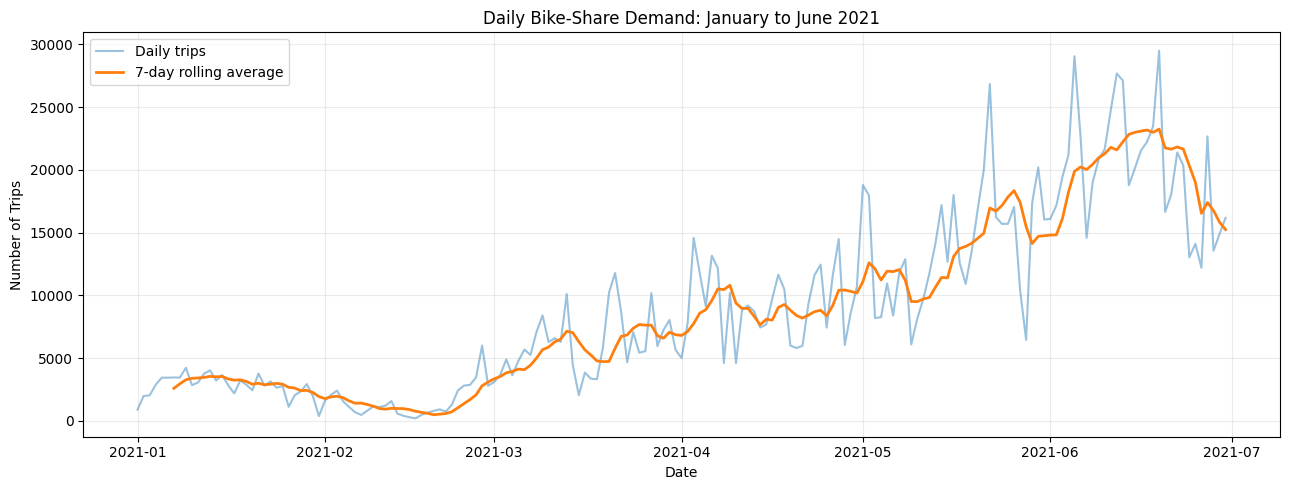

In [52]:
plt.figure(figsize=(13, 5))

plt.plot(
    daily_rides.index,
    daily_rides.values,
    alpha=0.45,
    label="Daily trips"
)

plt.plot(
    daily_rides.index,
    daily_rides.rolling(7).mean(),
    linewidth=2,
    label="7-day rolling average"
)

plt.title("Daily Bike-Share Demand: January to June 2021")
plt.xlabel("Date")
plt.ylabel("Number of Trips")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Ploting average demand by day of the week

,average_daily_trips
date,
Monday,7905.0
Tuesday,8613.0
Wednesday,8730.0
Thursday,7981.0
Friday,8926.0
Saturday,11107.0
Sunday,9540.0


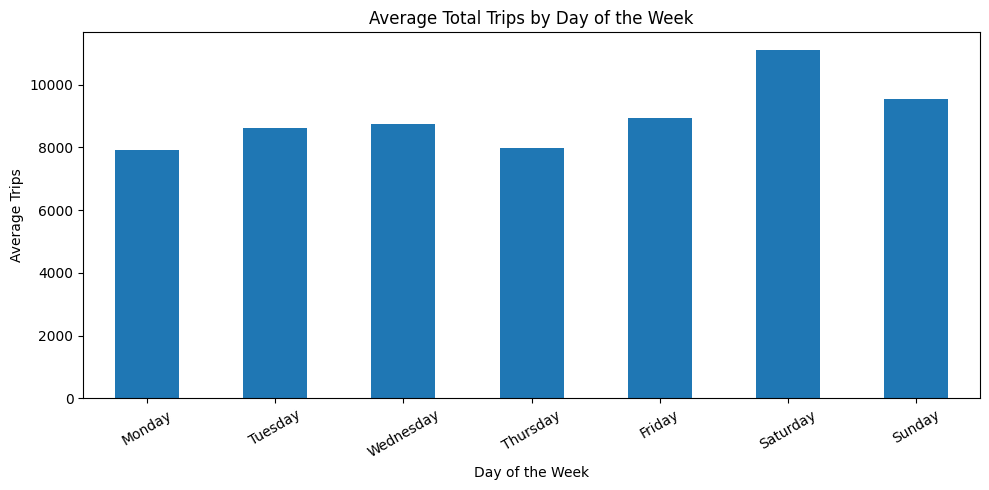

In [53]:
weekday_daily_average = (
    daily_rides.groupby(daily_rides.index.day_name())
               .mean()
               .reindex([
                   "Monday", "Tuesday", "Wednesday",
                   "Thursday", "Friday", "Saturday", "Sunday"
               ])
)

display(weekday_daily_average.round(0).to_frame("average_daily_trips"))

ax = weekday_daily_average.plot(
    kind="bar",
    figsize=(10, 5),
    rot=30
)

ax.set_title("Average Total Trips by Day of the Week")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Trips")
plt.tight_layout()
plt.show()

## Training and Test data
80% of dates for training and the final 20% for testing.

Split the time series

In [54]:
split_point = int(len(daily_rides) * 0.8)

train = daily_rides.iloc[:split_point]
test = daily_rides.iloc[split_point:]

print("Training observations:", len(train))
print("Training period:", train.index.min().date(), "to", train.index.max().date())

print("\nTesting observations:", len(test))
print("Testing period:", test.index.min().date(), "to", test.index.max().date())

Training observations: 144
Training period: 2021-01-01 to 2021-05-24

Testing observations: 37
Testing period: 2021-05-25 to 2021-06-30


Checking stationarity using the ADF test

In [55]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train)

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))
print("Critical values:")

for level, value in adf_result[4].items():
    print(f"{level}: {value:.4f}")

if adf_result[1] < 0.05:
    print("\nInterpretation: Reject the unit-root null hypothesis.")
else:
    print("\nInterpretation: Insufficient evidence to reject the unit-root null hypothesis.")

ADF statistic: 0.8655
p-value: 0.992624
Critical values:
1%: -3.4794
5%: -2.8830
10%: -2.5782

Interpretation: Insufficient evidence to reject the unit-root null hypothesis.


/tmp/ipykernel_20328/3624652420.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train)


Establish a simple baseline forecast

In [56]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Forecast each test day using the count from the previous week
baseline_predictions = daily_rides.shift(7).loc[test.index]

baseline_mae = mean_absolute_error(test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(test, baseline_predictions))

print("Weekly seasonal-naive baseline")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))

Weekly seasonal-naive baseline
MAE: 4877.59
RMSE: 6564.81
